# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Amran Belete, Nate Park, Amelia Chen, Lawson Pham

**Date:** 11/9/2026

In [12]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_csv('data/pierce_county_house_sales.csv', low_memory=False)

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.


df.shape:
(16814, 19) 

df.dtypes:
sale_date                      object
sale_price                      int64
house_square_feet               int64
attic_finished_square_feet      int64
basement_square_feet            int64
attached_garage_square_feet     int64
detached_garage_square_feet     int64
fireplaces                      int64
hvac_description               object
exterior                       object
interior                       object
stories                         int64
roof_cover                     object
year_built                      int64
bedrooms                        int64
bathrooms                       int64
waterfront_type                object
view_quality                   object
utility_sewer                  object
dtype: object 

    sale_date  sale_price  house_square_feet  attic_finished_square_feet  \
0  2020-01-02      380000               2157                           0   
1  2020-01-02      383000               2238                           0   

,Missing values
sale_date,0
hvac_description,7
exterior,1
interior,7
roof_cover,8
waterfront_type,16261
view_quality,15895
utility_sewer,0


,Missing values
sale_price,0
house_square_feet,0
attic_finished_square_feet,0
basement_square_feet,0
attached_garage_square_feet,0
detached_garage_square_feet,0
fireplaces,0
stories,0
year_built,0
bedrooms,0


C:\Users\npark\AppData\Local\Temp\ipykernel_41268\1992040039.py:57: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_categorical["waterfront_type"] = df_categorical["waterfront_type"].fillna("Not Recorded")
C:\Users\npark\AppData\Local\Temp\ipykernel_41268\1992040039.py:58: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_categorical["view_quality"] = df_categorical["view_quality"].fillna("Not Recorded")


,Missing values
sale_date,0
hvac_description,0
exterior,0
interior,0
roof_cover,0
waterfront_type,0
view_quality,0
utility_sewer,0


sale_price: 1012 outliers
house_square_feet: 174 outliers
attic_finished_square_feet: 1106 outliers
basement_square_feet: 2716 outliers
attached_garage_square_feet: 56 outliers
detached_garage_square_feet: 1077 outliers
fireplaces: 5630 outliers
stories: 0 outliers
year_built: 2 outliers
bedrooms: 524 outliers
bathrooms: 112 outliers


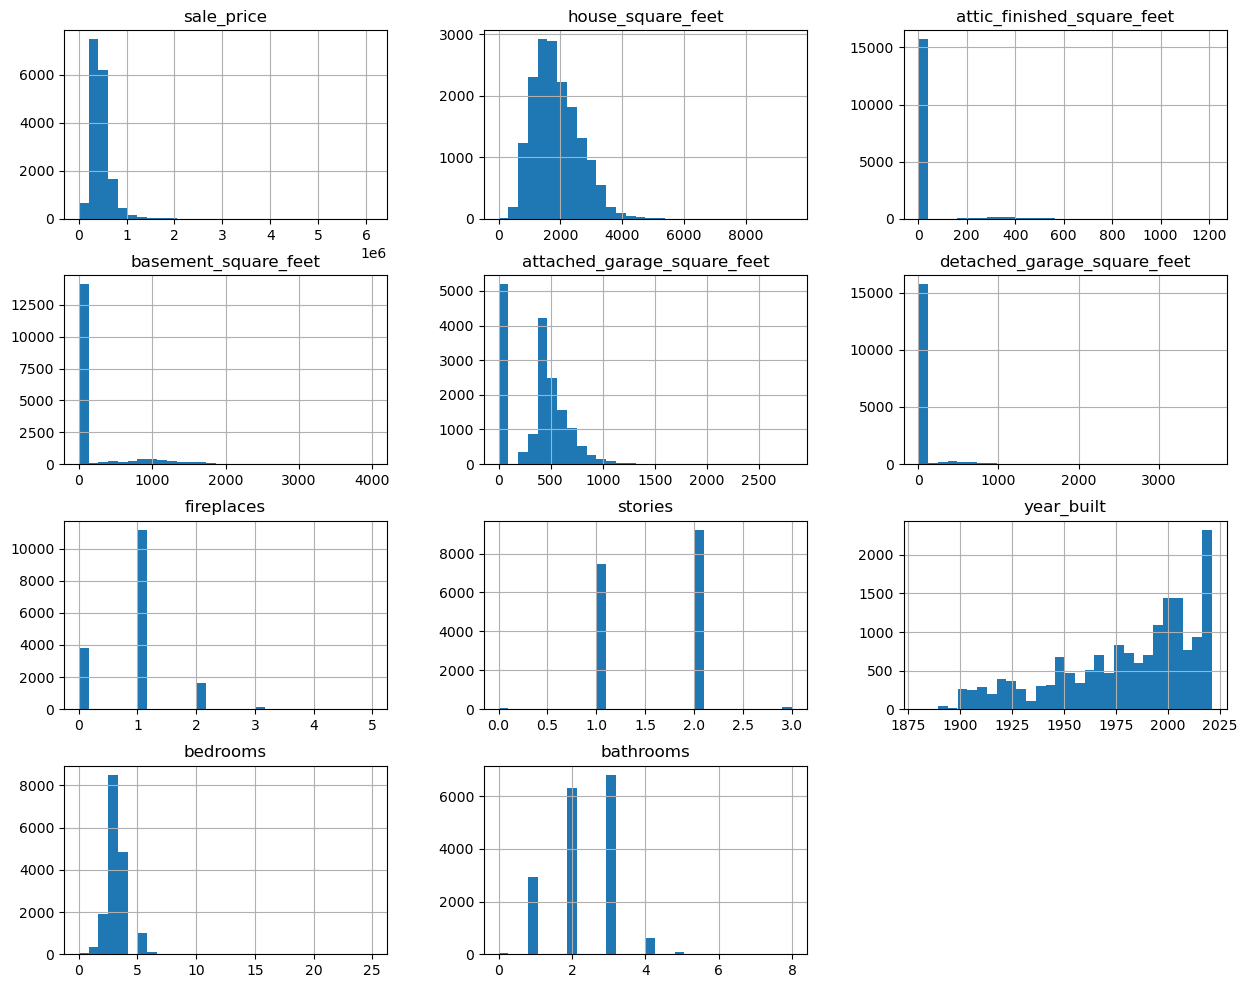

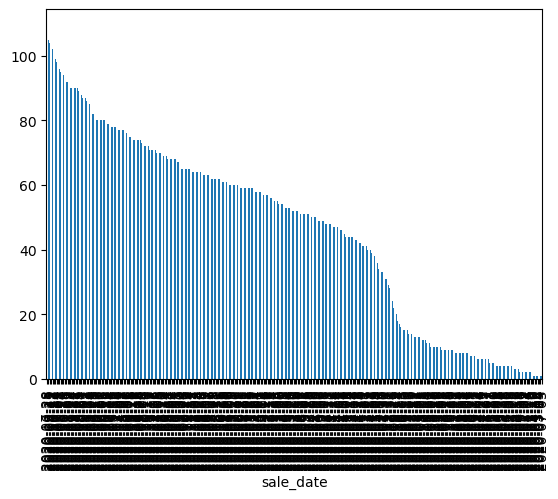

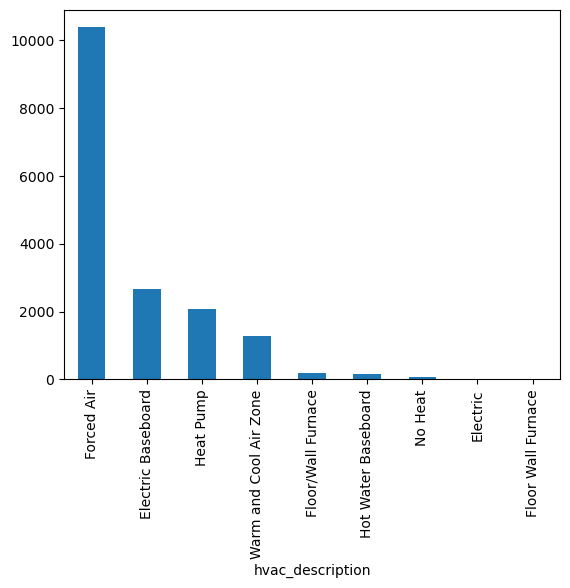

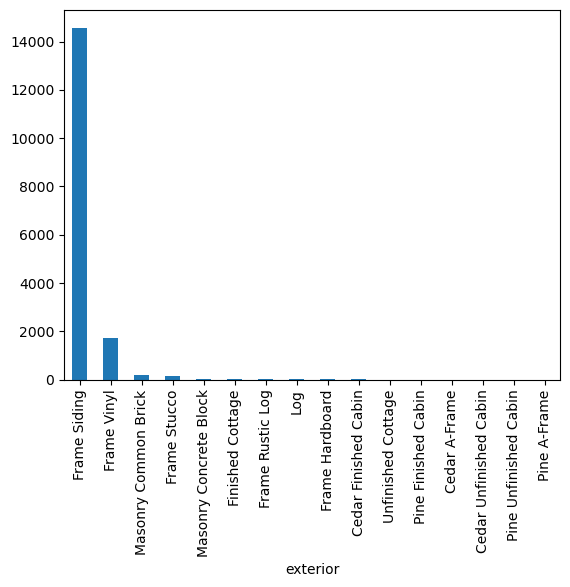

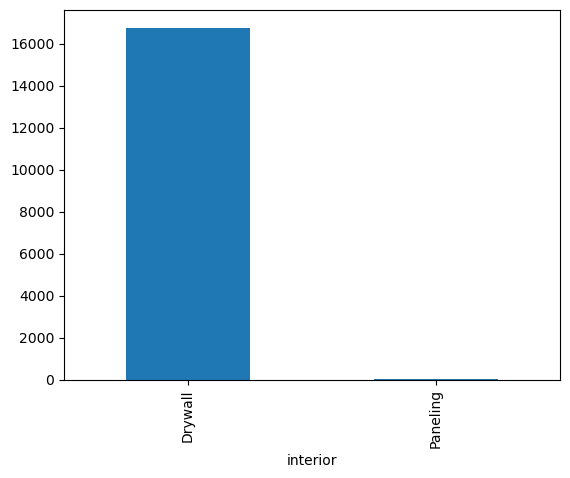

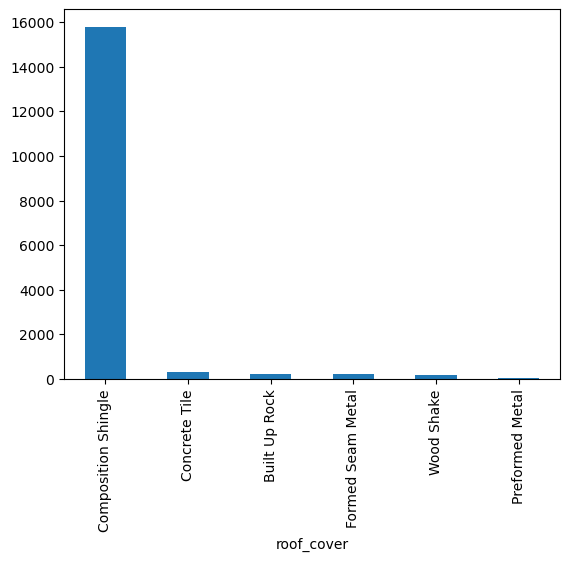

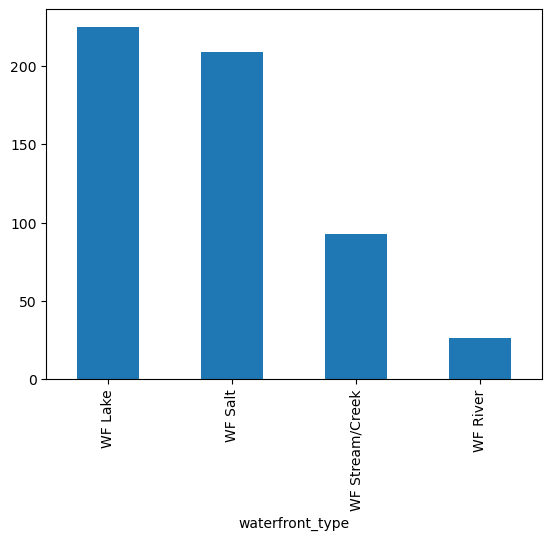

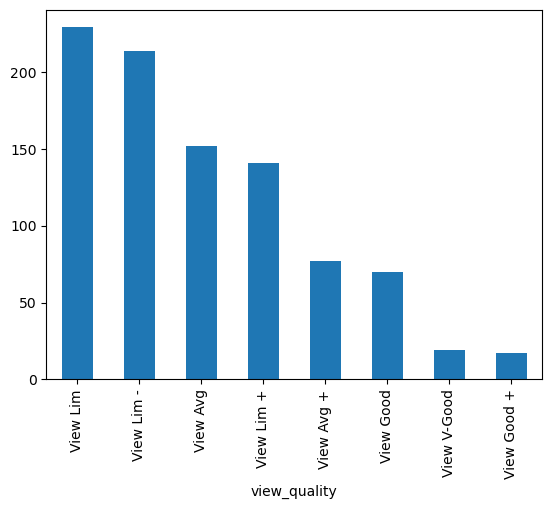

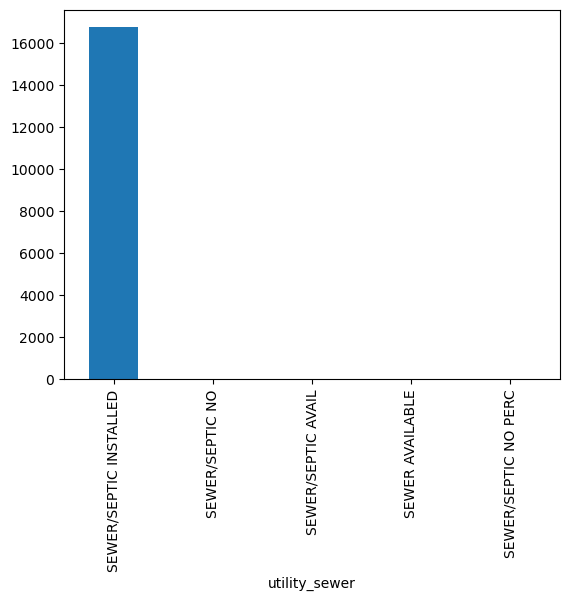

,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,1.681400e+04,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000,16814.000000
mean,4.612332e+05,1879.941953,24.945878,167.852861,364.425122,38.298501,0.889021,1.558285,1980.469252,3.277983,2.317176
std,2.360833e+05,760.419008,102.066417,429.065832,286.454018,164.691471,0.596731,0.512055,33.339025,0.891240,0.827956
min,2.000000e+03,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1880.000000,0.000000,0.000000
25%,3.480000e+05,1320.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1959.000000,3.000000,2.000000
50%,4.165000e+05,1774.000000,0.000000,0.000000,420.000000,0.000000,1.000000,2.000000,1990.000000,3.000000,2.000000
75%,5.238065e+05,2352.000000,0.000000,0.000000,528.000000,0.000000,1.000000,2.000000,2006.000000,4.000000,3.000000
max,6.130000e+06,9510.000000,1212.000000,4000.000000,2816.000000,3664.000000,5.000000,3.000000,2021.000000,25.000000,8.000000



sale_date:
sale_date
2020-07-28    109
2020-10-28    105
2020-09-23    104
2020-08-12    102
2020-07-23    102
             ... 
2020-01-12      1
2020-03-08      1
2020-03-15      1
2020-07-04      1
2020-07-05      1
Name: count, Length: 362, dtype: int64

hvac_description:
hvac_description
Forced Air                10382
Electric Baseboard         2668
Heat Pump                  2084
Warm and Cool Air Zone     1268
Floor/Wall Furnace          174
Hot Water Baseboard         146
No Heat                      82
NaN                           7
Electric                      2
Floor Wall Furnace            1
Name: count, dtype: int64

exterior:
exterior
Frame Siding              14577
Frame Vinyl                1724
Masonry Common Brick        208
Frame Stucco                156
Masonry Concrete Block       43
Finished Cottage             41
Frame Rustic Log             21
Log                          12
Frame Hardboard              11
Cedar Finished Cabin          5
Unfinished Cottage 

In [ ]:
print("df.shape:")
print(df.shape, '\n')

print("df.dtypes:")
print(df.dtypes, '\n')

print(df.head())

# Separate categorical and numeric variables
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()

'''
print("Categorical variables:", categorical_cols)
print("\nNumeric variables:", numeric_cols)

Categorical variables: ['sale_date', 'hvac_description', 'exterior', 'interior', 'roof_cover', 
'waterfront_type', 'view_quality', 'utility_sewer']

Numeric variables: ['sale_price', 'house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 
'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms']

'''

# Create separate dataframes for the categorical/numeric variables
df_categorical = df[categorical_cols]
df_numeric = df[numeric_cols]

# Check for missing values in each df
display(df_categorical.isna().sum().to_frame("Missing values"))
display(df_numeric.isna().sum().to_frame("Missing values"))

'''
We noticed that there are 16261 missing values for waterfront_type and 15895 missing values for view_quality.
The csv has 16814 entries in total, so a majority of entries are missing these values. Therefore, it is not a vaiable
option to drop the missing data, so we are choosing to label it as "not recorded." 

Additionally, there are 7 missing values for hvac_description, 1 for exterior, 7 for interior, and 8 for roof_cover.
Since there are only a few missing values for these variables, and we have a large amount of data in total, we are choosing
to drop these rows.

There are no missing numeric values.
'''

# Fill missing values
df_categorical["waterfront_type"] = df_categorical["waterfront_type"].fillna("Not Recorded")
df_categorical["view_quality"] = df_categorical["view_quality"].fillna("Not Recorded")

# Drop rows with missing hvac_description/exterior/interior/roof_cover values
df_categorical = df_categorical.dropna(subset=["hvac_description", "exterior", "interior", "roof_cover"])

# Check that missing values were filled
display(df_categorical.isna().sum().to_frame("Missing values"))

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col}: {len(outliers)} outliers")

df_numeric.hist(figsize=(15, 12), bins=30)
plt.show()

for col in categorical_cols:
    plt.figure()
    df[col].value_counts().plot(kind="bar")
    plt.show()

display(df_numeric.describe())

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


2. Transform your variables - particularly categorical ones - for use in your regression analysis.


3. Implement an 80/20 train-test split. Put the test data aside.


4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?


5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 


6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?


7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?


8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]